Import Libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Load the Clean the data

In [ ]:
df = pd.read_csv('/content/household_power_consumption.txt', sep= ";",na_values=["?"],low_memory = False)

In [ ]:
print(df.head())

         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [ ]:
print(df.tail())

            Date      Time  Global_active_power  Global_reactive_power  \
64622  30/1/2007  14:26:00                0.824                  0.128   
64623  30/1/2007  14:27:00                0.824                  0.128   
64624  30/1/2007  14:28:00                0.796                  0.088   
64625  30/1/2007  14:29:00                0.752                  0.000   
64626  30/1/2007    14:30:                  NaN                    NaN   

       Voltage  Global_intensity  Sub_metering_1  Sub_metering_2  \
64622   244.20               3.4             0.0             0.0   
64623   244.29               3.4             0.0             0.0   
64624   244.04               3.4             0.0             0.0   
64625   243.51               3.2             0.0             0.0   
64626      NaN               NaN             NaN             NaN   

       Sub_metering_3  
64622             0.0  
64623             0.0  
64624             0.0  
64625             0.0  
64626             NaN  


In [ ]:
print(df.shape)

(64627, 9)


In [ ]:
print(df["Global_active_power"].isna().sum())

7


Building a timestamp from Data and Time

In [ ]:
df["timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

In [ ]:
df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"], errors="coerce"
)

In [ ]:
df = df.dropna(subset=["timestamp"]).sort_values("timestamp")
df = df.set_index("timestamp")

convert minute-level readings into hourly average consumption

In [ ]:
hourly = df["Global_active_power"].resample("h").mean().to_frame()
hourly = hourly.rename(columns={"Global_active_power": "actual_kW"})

Fill only short gaps (up to 3 consecutive missing hourly values).

In [ ]:
hourly["actual_kW"] = hourly["actual_kW"].interpolate(
    method="time", limit=3
)
hourly = hourly.dropna()

print("\\nHourly data shape:", hourly.shape)
print("First timestamp:", hourly.index.min())
print("Last timestamp:", hourly.index.max())
print(hourly.head())

\nHourly data shape: (1078, 1)
First timestamp: 2006-12-16 17:00:00
Last timestamp: 2007-01-30 14:00:00
                     actual_kW
timestamp                     
2006-12-16 17:00:00   4.222889
2006-12-16 18:00:00   3.632200
2006-12-16 19:00:00   3.400233
2006-12-16 20:00:00   3.268567
2006-12-16 21:00:00   3.056467


plot hourly electricity consumption

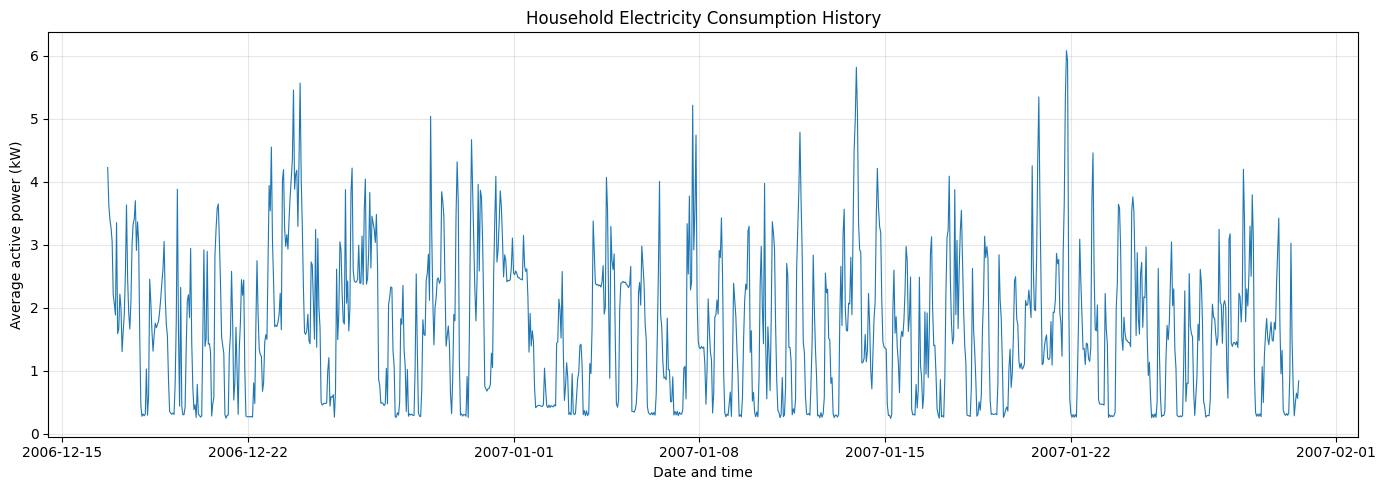

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(hourly.index, hourly["actual_kW"], linewidth=0.8)
plt.title("Household Electricity Consumption History")
plt.xlabel("Date and time")
plt.ylabel("Average active power (kW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



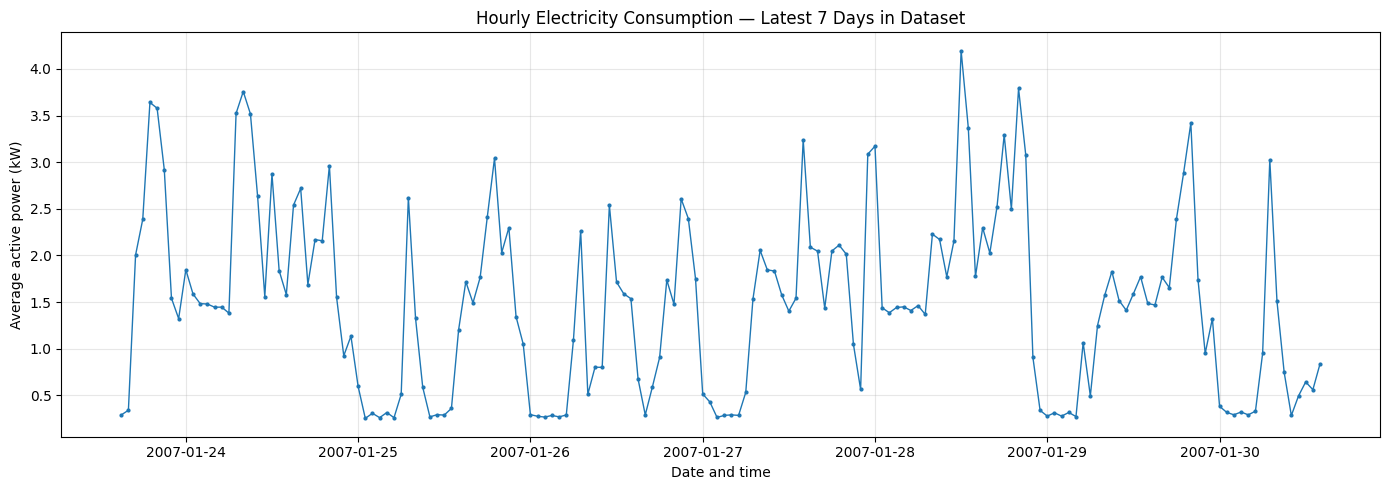

In [ ]:
# A closer view: the latest 7 days in the cleaned dataset.
plt.figure(figsize=(14, 5))
plt.plot(hourly.index[-24*7:], hourly["actual_kW"].tail(24*7), marker="o",
         markersize=2, linewidth=1)
plt.title("Hourly Electricity Consumption — Latest 7 Days in Dataset")
plt.xlabel("Date and time")
plt.ylabel("Average active power (kW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Split the time series correctly

In [ ]:
values = hourly[["actual_kW"]].values.astype("float32")
n = len(values)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled_values = scaler.transform(values)

print("Total hourly rows:", n)
print("Train boundary:", hourly.index[train_end - 1])
print("Validation boundary:", hourly.index[val_end - 1])
print("Test begins:", hourly.index[val_end])

Total hourly rows: 1078
Train boundary: 2007-01-17 02:00:00
Validation boundary: 2007-01-23 20:00:00
Test begins: 2007-01-23 21:00:00


Create sequences previous: 24 houes-- next hour

In [ ]:
LOOKBACK = 24  # use the previous 24 hourly readings

X, y, target_positions = [], [], []

for target_pos in range(LOOKBACK, len(scaled_values)):
    X.append(scaled_values[target_pos-LOOKBACK:target_pos])
    y.append(scaled_values[target_pos])
    target_positions.append(target_pos)

X = np.array(X, dtype="float32")
y = np.array(y, dtype="float32")
target_positions = np.array(target_positions)

train_mask = target_positions < train_end
val_mask = (target_positions >= train_end) & (target_positions < val_end)
test_mask = target_positions >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]
test_positions = target_positions[test_mask]
test_dates = hourly.index[test_positions]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)
print("Each input has 24 hours and 1 feature.")

X_train: (730, 24, 1) y_train: (730, 1)
X_val:   (162, 24, 1) y_val:   (162, 1)
X_test:  (162, 24, 1) y_test:  (162, 1)
Each input has 24 hours and 1 feature.


Build and trian the LSTM Model

In [ ]:
model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - loss: 0.0640 - mae: 0.2003 - val_loss: 0.0544 - val_mae: 0.1923
Epoch 2/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0441 - mae: 0.1718 - val_loss: 0.0516 - val_mae: 0.1743
Epoch 3/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0426 - mae: 0.1690 - val_loss: 0.0494 - val_mae: 0.1777
Epoch 4/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0401 - mae: 0.1659 - val_loss: 0.0488 - val_mae: 0.1729
Epoch 5/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0404 - mae: 0.1661 - val_loss: 0.0478 - val_mae: 0.1727
Epoch 6/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0390 - mae: 0.1641 - val_loss: 0.0474 - val_mae: 0.1722
Epoch 7/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0391 - mae: 0.1642 - val_loss: 0.0466 - val_mae: 0.1714
Epoch 8/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0389 - mae: 0.1629 - val_loss: 0.0461 - val_mae: 0.1699
Epoch 9/15
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.037

plot training and validation loss

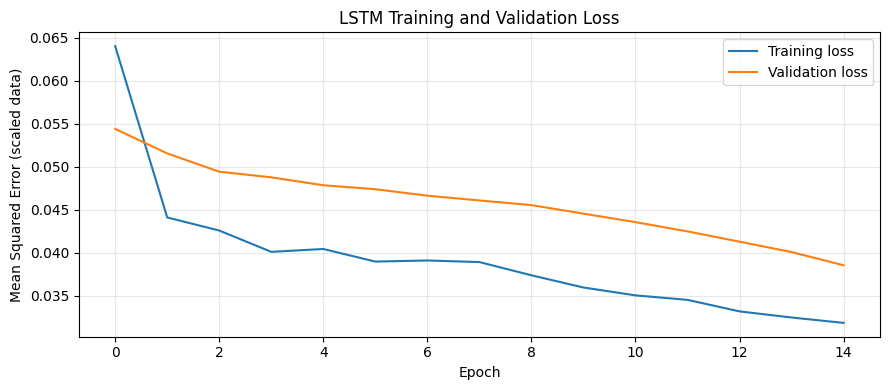

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (scaled data)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Evaluate the model against a simple baseline

In [ ]:

pred_scaled = model.predict(X_test, verbose=0)
y_test_kw = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
pred_kw = scaler.inverse_transform(pred_scaled).ravel()


last_input_scaled = X_test[:, -1, 0].reshape(-1, 1)
baseline_kw = scaler.inverse_transform(last_input_scaled).ravel()

def report_metrics(actual, predicted, label):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f"{label}: MAE = {mae:.4f} kW | RMSE = {rmse:.4f} kW")
    return {"Model": label, "MAE (kW)": mae, "RMSE (kW)": rmse}

results = [
    report_metrics(y_test_kw, pred_kw, "LSTM"),
    report_metrics(y_test_kw, baseline_kw, "Persistence baseline")
]

metrics_df = pd.DataFrame(results)
display(metrics_df)

if metrics_df.loc[0, "MAE (kW)"] < metrics_df.loc[1, "MAE (kW)"]:
    print("On this test split, LSTM has lower MAE than the baseline.")
else:
    print("On this test split, LSTM does not have lower MAE than the baseline.")

LSTM: MAE = 0.6713 kW | RMSE = 0.8320 kW
Persistence baseline: MAE = 0.5234 kW | RMSE = 0.7599 kW


,Model,MAE (kW),RMSE (kW)
0,LSTM,0.671293,0.831979
1,Persistence baseline,0.523380,0.759873


On this test split, LSTM does not have lower MAE than the baseline.


plot actual vs predicted consumption(main result graph)

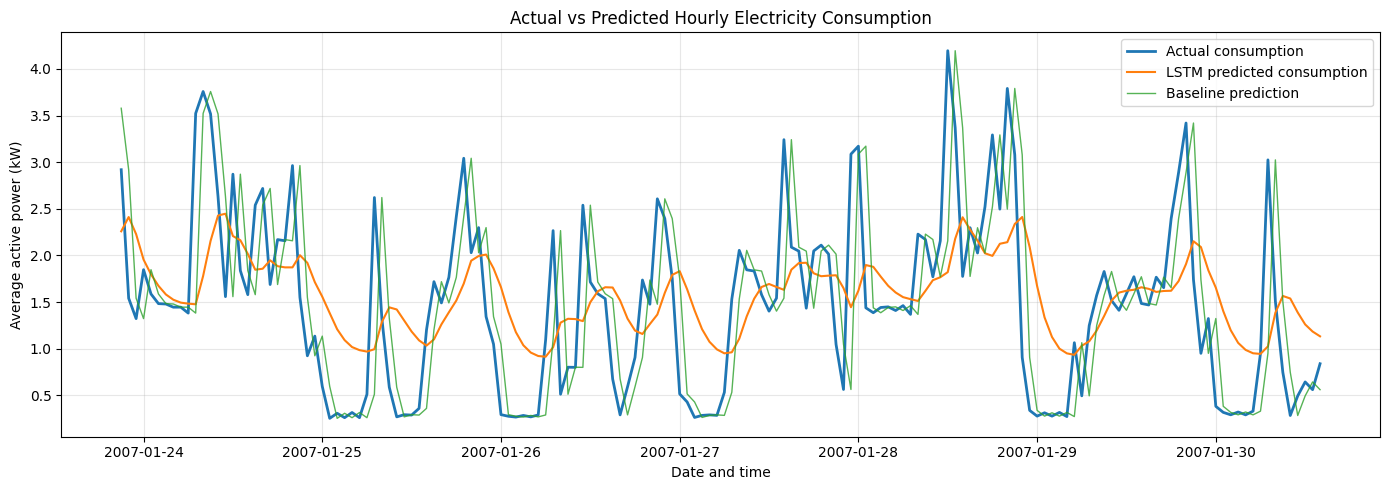

In [ ]:

days_to_show = min(7 * 24, len(y_test_kw))

plt.figure(figsize=(14, 5))
plt.plot(test_dates[:days_to_show], y_test_kw[:days_to_show],
         label="Actual consumption", linewidth=2)
plt.plot(test_dates[:days_to_show], pred_kw[:days_to_show],
         label="LSTM predicted consumption", linewidth=1.5)
plt.plot(test_dates[:days_to_show], baseline_kw[:days_to_show],
         label="Baseline prediction", linewidth=1, alpha=0.8)
plt.title("Actual vs Predicted Hourly Electricity Consumption")
plt.xlabel("Date and time")
plt.ylabel("Average active power (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

show an output table

In [ ]:
predictions_df = pd.DataFrame({
    "timestamp": test_dates,
    "actual_kW": y_test_kw,
    "lstm_predicted_kW": pred_kw,
    "baseline_predicted_kW": baseline_kw
}).set_index("timestamp")

display(predictions_df.head(10).round(3))

,actual_kW,lstm_predicted_kW,baseline_predicted_kW
timestamp,,,
2007-01-23 21:00:00,2.919,2.259,3.579
2007-01-23 22:00:00,1.541,2.412,2.919
2007-01-23 23:00:00,1.323,2.229,1.541
2007-01-24 00:00:00,1.847,1.956,1.323
2007-01-24 01:00:00,1.587,1.798,1.847
2007-01-24 02:00:00,1.483,1.674,1.587
2007-01-24 03:00:00,1.479,1.582,1.483
2007-01-24 04:00:00,1.445,1.525,1.479
2007-01-24 05:00:00,1.446,1.494,1.445


Forecast the next Hour after the latest available date

In [ ]:
last_24_scaled = scaled_values[-LOOKBACK:].reshape(1, LOOKBACK, 1)
next_scaled = model.predict(last_24_scaled, verbose=0)
next_hour_kw = float(scaler.inverse_transform(next_scaled)[0, 0])
next_timestamp = hourly.index[-1] + pd.Timedelta(hours=1)

print("Latest available hourly timestamp:", hourly.index[-1])
print("Forecast timestamp:", next_timestamp)
print(f"Predicted average active power: {next_hour_kw:.3f} kW")

Latest available hourly timestamp: 2007-01-30 14:00:00
Forecast timestamp: 2007-01-30 15:00:00
Predicted average active power: 1.135 kW
